# Credit card default: logistic regression from scratch

Input: `data/curated/credit_default.csv`, made by `eda.ipynb` (see that notebook for what each feature means). If the file is missing, the data-split cell runs `eda.ipynb` first, which downloads the raw data from UCI.

In [1]:
import os
import subprocess
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scienceplots
import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)  # silence CMU font-weight warnings

CURATED = '../data/curated/credit_default.csv'
PLOTS = '../plots'
MONTHS = ['sep', 'aug', 'jul', 'jun', 'may', 'apr']

plt.style.use(['science', 'no-latex', 'grid'])
plt.rcParams.update({
    'figure.dpi': 120, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'font.family': 'sans-serif', 'font.sans-serif': ['CMU Sans Serif'],
    'mathtext.fontset': 'custom', 'mathtext.rm': 'CMU Sans Serif',
    'mathtext.it': 'CMU Sans Serif:italic', 'mathtext.bf': 'CMU Sans Serif:bold',
    'axes.unicode_minus': False, 'axes.formatter.use_mathtext': False,  # CMU has no Unicode minus glyph
})

## Data split
**80% development, 20% test.**
- **test** (6,000 ids): used once, for the final numbers. Test clients are chosen by id, so the same clients stay in the test set even if the cleaning drops a row. With about 1,300 defaulters, the test AUC has a standard error of about 0.008 (see the end of the notebook). A 1,000-client test set would give about 0.016, too noisy to tell models apart.
- **development** (the other 24,000): split into 5 folds for cross-validation. Each candidate model is fit on 4 folds and scored on the 5th, five times over, so every development client is used both to fit and to score. This makes the feature choice less noisy than scoring on one fixed validation set. After selection, the final model is refit on all development clients.

Each cross-validation fit uses about 19,000 clients. That is plenty: with the final features, validation AUC is 0.775 when trained on 1,000 clients, 0.782 on 5,000 and 0.783 on 18,000.

In [ ]:
if not os.path.exists(CURATED):  # data/ is not in the repo: build it with the EDA notebook
    subprocess.run([sys.executable, '-m', 'nbconvert', '--to', 'notebook', '--execute', '--inplace', 'eda.ipynb'], check=True)
df = pd.read_csv(CURATED)
y = df['default'].values

rng = np.random.default_rng(42)
test_ids = rng.choice(np.arange(1, 30001), size=6000, replace=False)
is_test = df['id'].isin(test_ids).values
test_idx = np.flatnonzero(is_test)

dev_idx = np.flatnonzero(~is_test)
rng.shuffle(dev_idx)
folds = np.array_split(dev_idx, 5)
len(dev_idx), len(test_idx), [len(f) for f in folds]

In [ ]:
fig, ax = plt.subplots(figsize=(8, 2.2))
left = 0
for k, idx in enumerate(folds + [test_idx]):
    share = len(idx) / len(df)
    mid = left + share / 2
    is_test_part = k == len(folds)
    ax.barh(0, share, left=left, height=1, color='C1' if is_test_part else 'C0', edgecolor='white', linewidth=2)
    name = 'test' if is_test_part else f'fold {k + 1}'
    ax.text(mid, 0.22, f'{name}\n{share:.0%}', ha='center', va='center', color='white', fontsize=10)
    ax.text(mid, -0.25, f'{len(idx):,} clients\n{y[idx].sum():,} defaulters', ha='center', va='center', color='white', fontsize=7)
    left += share

dev_share = len(dev_idx) / len(df)
ax.annotate('', xy=(0, -0.68), xytext=(dev_share, -0.68), arrowprops=dict(arrowstyle='|-|', lw=0.8))
ax.text(dev_share / 2, -1.0, f'development {dev_share:.0%}: 5-fold cross-validation chooses features and threshold,\nthen the final model is refit on all of it',
        ha='center', va='center', fontsize=8.5)
ax.text(dev_share + (1 - dev_share) / 2, -1.0, 'final check,\nused once', ha='center', va='center', fontsize=8.5)
ax.set_xlim(0, 1)
ax.set_ylim(-1.25, 0.55)
ax.axis('off')
ax.set_title('Train / test split')
plt.savefig(f'{PLOTS}/data_split.png')
plt.show()

In [ ]:
parts = [(f'fold {k + 1}', idx) for k, idx in enumerate(folds)] + [('test', test_idx)]

fig, ax = plt.subplots(figsize=(6, 3.5))
for k, (name, idx) in enumerate(parts):
    rate = y[idx].mean()
    ax.bar(k, 1 - rate, color='C0', label='no default' if k == 0 else None)
    ax.bar(k, rate, bottom=1 - rate, color='C1', label='default' if k == 0 else None)
    ax.text(k, (1 - rate) / 2, f'{1 - rate:.1%}', ha='center', va='center', color='white', fontsize=8)
    ax.text(k, 1 - rate / 2, f'{rate:.1%}', ha='center', va='center', color='white', fontsize=8)
ax.set_xticks(range(len(parts)), [name for name, _ in parts])
ax.set_ylabel('share of clients')
ax.set_ylim(0, 1)
ax.grid(False)
ax.minorticks_off()
ax.set_title('Class balance in each set')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
plt.savefig(f'{PLOTS}/class_balance.png')
plt.show()

## Scaling
Each feature is standardized with the mean and SD of the clients the model is **fit on** (`ref`), never the clients it is scored on. All features are then on the same scale, so one learning rate works for every parameter. A column of 1s is added for the intercept.

In [ ]:
def make_matrix(cols, idx, ref):
    fit_on = df[cols].values[ref]
    mu, sd = fit_on.mean(axis=0), fit_on.std(axis=0)
    A = (df[cols].values[idx] - mu) / sd
    return np.column_stack([np.ones(len(idx)), A])

## The model

For client $i$ with features $x_i$, the probability of default is

$$p_i = \sigma(x_i^\top \beta) = \frac{1}{1 + e^{-x_i^\top \beta}}$$

**Likelihood.** Each client contributes $p_i$ if they defaulted ($y_i = 1$) and $1 - p_i$ if they didn't ($y_i = 0$):

$$L(\beta) = \prod_i p_i^{\,y_i} (1 - p_i)^{1 - y_i}$$

**Log-likelihood (the score we maximize).** The product of thousands of numbers below 1 underflows to 0, so take logs:

$$\ell(\beta) = \sum_i \Big[ y_i \log p_i + (1 - y_i) \log(1 - p_i) \Big]$$

**Gradient.** Using $\sigma'(z) = \sigma(z)(1 - \sigma(z))$:

$$\frac{\partial \ell}{\partial \beta_j} = \sum_i (y_i - p_i)\, x_{ij}$$

**Update (gradient ascent).** Move each parameter up if its derivative is positive, down if negative:

$$\beta_j \leftarrow \beta_j + \eta \cdot \frac{1}{n} \frac{\partial \ell}{\partial \beta_j}$$

In [6]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def log_likelihood(beta, X, y):
    p = np.clip(sigmoid(X @ beta), 1e-12, 1 - 1e-12)
    return np.sum(y * np.log(p) + (1 - y) * np.log(1 - p))

def fit(X, y, lr=0.5, n_iter=3000, track=False):
    """Gradient ascent. With track=True, also record the log-likelihood after every step."""
    beta = np.zeros(X.shape[1])
    history = []
    for _ in range(n_iter):
        p = sigmoid(X @ beta)
        beta = beta + lr * X.T @ (y - p) / len(y)
        if track:
            history.append(log_likelihood(beta, X, y))
    return beta, history

## Evaluation helpers
`cv_proba` gives every development client a prediction from a model that never saw them. `cv_log_likelihood` scores those predictions; forward selection uses it to compare feature sets.

In [ ]:
def confusion(y, pred):
    tp = np.sum((pred == 1) & (y == 1))
    fp = np.sum((pred == 1) & (y == 0))
    fn = np.sum((pred == 0) & (y == 1))
    tn = np.sum((pred == 0) & (y == 0))
    return tp, fp, fn, tn

def roc(y, proba):
    y_sorted = y[np.argsort(-proba)]
    tpr = np.concatenate([[0], np.cumsum(y_sorted) / y.sum()])
    fpr = np.concatenate([[0], np.cumsum(1 - y_sorted) / (1 - y).sum()])
    return fpr, tpr, np.trapezoid(tpr, fpr)

def cv_proba(cols, lr=0.5, n_iter=3000):
    """Out-of-fold predictions for every development client: fit on 4 folds, predict the 5th."""
    p = np.full(len(df), np.nan)
    for k, hold in enumerate(folds):
        fit_idx = np.concatenate(folds[:k] + folds[k + 1:])
        b, _ = fit(make_matrix(cols, fit_idx, fit_idx), y[fit_idx], lr, n_iter)
        p[hold] = sigmoid(make_matrix(cols, hold, fit_idx) @ b)
    return p[dev_idx]

def cv_log_likelihood(cols, lr=1.0, n_iter=300):
    p = np.clip(cv_proba(cols, lr, n_iter), 1e-12, 1 - 1e-12)
    y_dev = y[dev_idx]
    return np.sum(y_dev * np.log(p) + (1 - y_dev) * np.log(1 - p))

## Base model
The original features, no transformations.

In [ ]:
base_features = (['credit_limit', 'age'] + [f'late_{m}' for m in MONTHS] + [f'bill_{m}' for m in MONTHS]
                 + [f'paid_{m}' for m in MONTHS]
                 + ['female', 'edu_university', 'edu_high_school', 'edu_other', 'single', 'marital_other'])

X_dev = make_matrix(base_features, dev_idx, dev_idx)
X_test = make_matrix(base_features, test_idx, dev_idx)
beta_base, history = fit(X_dev, y[dev_idx], track=True)
avg_ll = np.array(history) / len(dev_idx)
print(f'average log-likelihood per client: start {np.log(0.5):.3f}, end {avg_ll[-1]:.3f}')
proba_base = sigmoid(X_test @ beta_base)

plt.plot(np.arange(1, len(avg_ll) + 1), avg_ll)
plt.xscale('log')
plt.xlabel('iteration')
plt.ylabel('average log-likelihood')
plt.title('Average log-likelihood vs iteration')
plt.savefig(f'{PLOTS}/lr_log_likelihood.png')
plt.show()

## Forward selection
Candidates: the base features with the money columns logged, plus the new features and interaction terms from the EDA.

Start with only the intercept. At each step, add the candidate that raises the **cross-validated** log-likelihood the most. Stop when no candidate raises it by at least 8. The score is summed over 24,000 clients, so 8 is the same bar per client as 2 on a 6,000-client validation set (about 0.0003). With a cutoff of 2, the search keeps going to 22 features but only moves the average log-likelihood from −0.433 to −0.432. (Fits inside the search use 300 iterations with learning rate 1.0 for speed.)

In [ ]:
candidates = (['log_credit_limit', 'age'] + [f'late_{m}' for m in MONTHS]
              + ['late_sep_m2', 'late_sep_m1', 'late_sep_1', 'late_sep_2', 'late_sep_3plus']
              + [f'log_bill_{m}' for m in MONTHS] + [f'log_paid_{m}' for m in MONTHS]
              + [f'util_{m}' for m in MONTHS] + ['months_late', 'credit_balance_months']
              + ['late_x_util', 'late_x_limit', 'months_late_x_util', 'age_x_limit', 'late_sep_x_aug']
              + ['female', 'edu_university', 'edu_high_school', 'edu_other', 'single', 'marital_other'])

selected = []
best = cv_log_likelihood([])
while True:
    tries = {c: cv_log_likelihood(selected + [c]) for c in candidates if c not in selected}
    c = max(tries, key=tries.get)
    if tries[c] - best < 8:
        break
    selected.append(c)
    best = tries[c]
    print(f'+ {c:20s} cross-validated average log-likelihood {best / len(dev_idx):.4f}')

## Final model
Refit the selected features on all development clients. The threshold is chosen on the out-of-fold predictions so the model catches about 65% of defaulters. Those are honest predictions for clients each model never saw, so the test set is not touched.

In [ ]:
beta, _ = fit(make_matrix(selected, dev_idx, dev_idx), y[dev_idx])
proba = sigmoid(make_matrix(selected, test_idx, dev_idx) @ beta)
proba_oof = cv_proba(selected)
y_dev = y[dev_idx]

thresholds = np.arange(0.05, 0.9, 0.01)
oof_recall = [confusion(y_dev, (proba_oof >= t).astype(int))[0] / y_dev.sum() for t in thresholds]
threshold = thresholds[np.array(oof_recall) >= 0.65].max()
print(f'threshold: {threshold:.2f}')

For comparison, the thresholds other criteria would pick on the same out-of-fold predictions. If a missed defaulter costs *k* false alarms, perfectly calibrated probabilities give an optimum at 1/(1 + *k*).

In [ ]:
def errors(t):
    tp, fp, fn, tn = confusion(y_dev, (proba_oof >= t).astype(int))
    return tp, fp, fn, tn

criteria = {
    'accuracy': lambda tp, fp, fn, tn: tp + tn,
    'F1': lambda tp, fp, fn, tn: 2 * tp / (2 * tp + fp + fn),
    "Youden's J": lambda tp, fp, fn, tn: tp / (tp + fn) + tn / (tn + fp) - 1,
    'cost k=2': lambda tp, fp, fn, tn: -(2 * fn + fp),
    'cost k=3': lambda tp, fp, fn, tn: -(3 * fn + fp),
    'cost k=5': lambda tp, fp, fn, tn: -(5 * fn + fp),
}
for name, score in criteria.items():
    t = max(thresholds, key=lambda t: score(*errors(t)))
    print(f'{name:12s} {t:.2f}')

## Results on the test set

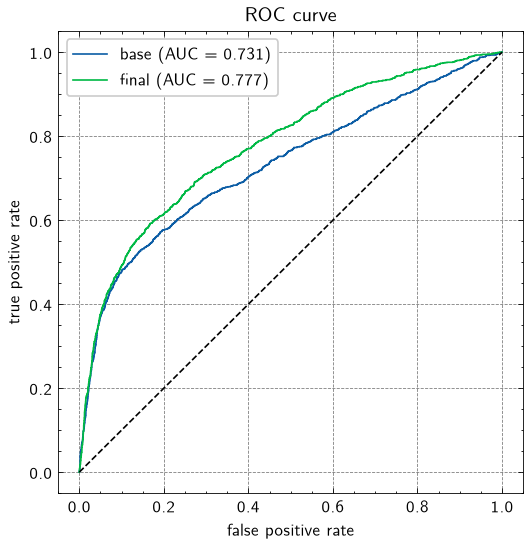

In [11]:
y_test = y[test_idx]
fpr_b, tpr_b, auc_b = roc(y_test, proba_base)
fpr_f, tpr_f, auc_f = roc(y_test, proba)

plt.figure(figsize=(5, 5))
plt.plot(fpr_b, tpr_b, label=f'base (AUC = {auc_b:.3f})')
plt.plot(fpr_f, tpr_f, label=f'final (AUC = {auc_f:.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('false positive rate')
plt.ylabel('true positive rate')
plt.title('ROC curve')
plt.legend()
plt.savefig(f'{PLOTS}/lr_roc.png')
plt.show()

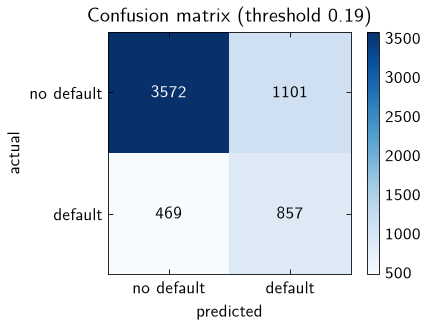

caught 857 of 1326 defaulters, 1101 false alarms


In [12]:
tp, fp, fn, tn = confusion(y_test, (proba >= threshold).astype(int))
cm = np.array([[tn, fp], [fn, tp]])
labels = ['no default', 'default']

plt.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center',
                 color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.xticks([0, 1], labels)
plt.yticks([0, 1], labels)
plt.grid(False)
plt.minorticks_off()
plt.xlabel('predicted')
plt.ylabel('actual')
plt.title(f'Confusion matrix (threshold {threshold:.2f})')
plt.colorbar()
plt.savefig(f'{PLOTS}/lr_confusion_matrix.png')
plt.show()

print(f'caught {tp} of {tp + fn} defaulters, {fp} false alarms')

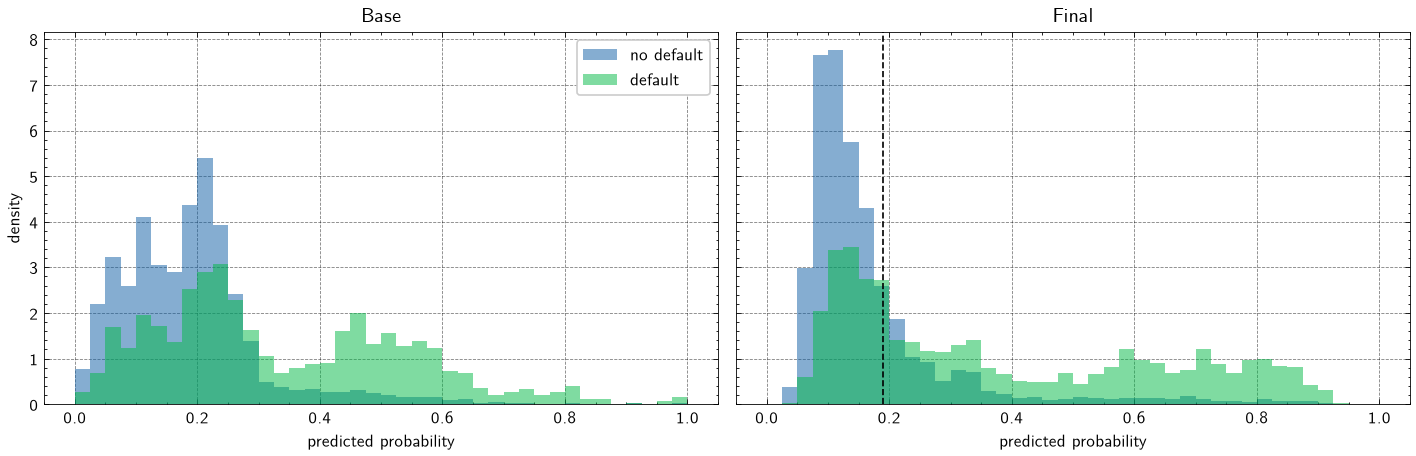

In [13]:
bins = np.linspace(0, 1, 41)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, name, pr in [(axes[0], 'Base', proba_base), (axes[1], 'Final', proba)]:
    ax.hist(pr[y_test == 0], bins=bins, alpha=0.5, density=True, label='no default')
    ax.hist(pr[y_test == 1], bins=bins, alpha=0.5, density=True, label='default')
    ax.set_xlabel('predicted probability')
    ax.set_title(name)
axes[1].axvline(threshold, color='k', linestyle='--')
axes[0].set_ylabel('density')
axes[0].legend()
plt.tight_layout()
plt.savefig(f'{PLOTS}/lr_probability_distribution.png')
plt.show()

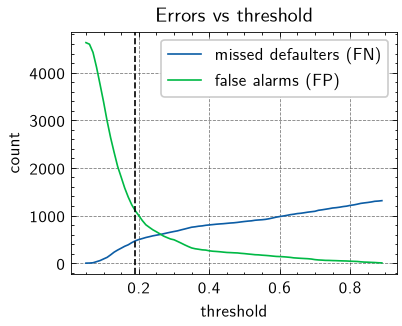

In [14]:
fn_counts = [confusion(y_test, (proba >= t).astype(int))[2] for t in thresholds]
fp_counts = [confusion(y_test, (proba >= t).astype(int))[1] for t in thresholds]

plt.plot(thresholds, fn_counts, label='missed defaulters (FN)')
plt.plot(thresholds, fp_counts, label='false alarms (FP)')
plt.axvline(threshold, color='k', linestyle='--')
plt.xlabel('threshold')
plt.ylabel('count')
plt.title('Errors vs threshold')
plt.legend()
plt.savefig(f'{PLOTS}/lr_errors_vs_threshold.png')
plt.show()

In [ ]:
coefs = pd.Series(beta[1:], index=selected).sort_values()

# re-run gradient ascent on the final features, recording the coefficients at every iteration
X = make_matrix(selected, dev_idx, dev_idx)
b = np.zeros(X.shape[1])
path = []
for _ in range(3000):
    b = b + 0.5 * X.T @ (y[dev_idx] - sigmoid(X @ b)) / len(dev_idx)
    path.append(b[1:].copy())
path = pd.DataFrame(path, columns=selected)

# one colour per feature, shared by the bars and the lines
palette = [plt.cm.tab20(i) for i in list(range(0, 20, 2)) + list(range(1, 20, 2))]
color = dict(zip(coefs.index[::-1], palette))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), width_ratios=[1, 1.3])
ax = axes[0]
ax.barh(coefs.index.str.replace('_', ' '), coefs.values, color=[color[n] for n in coefs.index])
ax.axvline(0, color='k', linewidth=0.8)
ax.set_xlabel('coefficient (standardized)')
ax.set_title('Coefficients')

ax = axes[1]
for name in coefs.index[::-1]:
    ax.plot(np.arange(1, len(path) + 1), path[name], color=color[name], label=name.replace('_', ' '))
ax.axhline(0, color='k', linewidth=0.8)
ax.set_xscale('log')
ax.set_xlabel('iteration')
ax.set_ylabel('coefficient (standardized)')
ax.set_title('Coefficients during gradient ascent')
ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig(f'{PLOTS}/lr_coefficients.png')
plt.show()

## How precise is the test AUC?
The AUC is the probability that a random defaulter gets a higher score than a random non-defaulter. On a finite test set it is an estimate, and its noise is dominated by the number of defaulters (about 1,300 here). Two ways to measure it:
- **Bootstrap**: resample the test clients with replacement 2,000 times and recompute the AUC each time; the SD of those AUCs is the standard error.
- **Hanley & McNeil (1982)**: a closed-form standard error from the AUC $A$ and the counts of defaulters $n_1$ and non-defaulters $n_0$:

$$SE^2 = \frac{A(1-A) + (n_1 - 1)(Q_1 - A^2) + (n_0 - 1)(Q_2 - A^2)}{n_1 n_0}, \quad Q_1 = \frac{A}{2 - A}, \quad Q_2 = \frac{2A^2}{1 + A}$$

The gain over the base model is measured on the same clients, so it is bootstrapped as a paired difference.

In [ ]:
def hanley_mcneil(A, n1, n0):
    q1, q2 = A / (2 - A), 2 * A**2 / (1 + A)
    return np.sqrt((A * (1 - A) + (n1 - 1) * (q1 - A**2) + (n0 - 1) * (q2 - A**2)) / (n1 * n0))

boot = np.random.default_rng(0)
auc_boot, gain_boot = [], []
for _ in range(2000):
    i = boot.integers(0, len(y_test), len(y_test))
    a_f, a_b = roc(y_test[i], proba[i])[2], roc(y_test[i], proba_base[i])[2]
    auc_boot.append(a_f)
    gain_boot.append(a_f - a_b)

n1, n0 = y_test.sum(), len(y_test) - y_test.sum()
print(f'final AUC {auc_f:.3f}')
print(f'  standard error: bootstrap {np.std(auc_boot):.4f}, Hanley-McNeil {hanley_mcneil(auc_f, n1, n0):.4f}')
print(f'  95% interval {np.percentile(auc_boot, 2.5):.3f} to {np.percentile(auc_boot, 97.5):.3f}')
print(f'gain over base {auc_f - auc_b:.3f}, 95% interval {np.percentile(gain_boot, 2.5):.3f} to {np.percentile(gain_boot, 97.5):.3f}')
print(f'a 1,000-client test set (~{round(1000 * y_test.mean())} defaulters) would give about '
      f'{hanley_mcneil(auc_f, round(1000 * y_test.mean()), 1000 - round(1000 * y_test.mean())):.4f}')